In [1]:
import os
import re
import pickle
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    Concatenate
)

from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

In [4]:
SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

In [5]:
DATA_PATH = "../../datasets/processed/email_classification_dataset.parquet"

df = pd.read_parquet(DATA_PATH)

print("Dataset shape:", df.shape)

Dataset shape: (5419, 11)


In [6]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Columns:
['file', 'message_id', 'date', 'sender', 'receiver', 'cc', 'bcc', 'subject', 'body', 'body_length', 'label']

Data types:
file           object
message_id     object
date           object
sender         object
receiver       object
cc             object
bcc            object
subject        object
body           object
body_length     int64
label          object
dtype: object


In [7]:
print(df.isnull().sum())

file           3782
message_id        0
date              0
sender            0
receiver          0
cc                0
bcc               0
subject           0
body              0
body_length       0
label             0
dtype: int64


In [8]:
df = df[
    [
        "sender",
        "subject",
        "body",
        "label"
    ]
].copy()

print(df.shape)
print(df.head())

(5419, 4)
                                              sender  \
0                           Vip-mail <vip@99-81.com>   
1                                     h433@excite.fr   
2                            amknight@mailexcite.com   
3  'Director TBI' via B.Tech. - Comp  Sci Engg 20...   
4  'Dean SENSE' via B.Tech. - Comp  Sci Engg 2023...   

                                             subject  \
0                                    未承諾広告※灼熱！出会いの広場   
1                            Your guide to a new job   
2  New Improved Fat Burners, Now With TV Fat Abso...   
3                    Fwd: VITTBI -Upcoming Workshops   
4  Industry expert lecture - 10/07/2026 @ 2.30PM ...   

                                                body      label  
0                                                          spam  
1                                                          spam  
2  *****Bonus Fat Absorbers As Seen On TV, Includ...       spam  
3  Please see the trailing mail for details/ regi...

In [9]:
for column in ["sender", "subject", "body"]:
    df[column] = df[column].fillna("").astype(str)

df["label"] = df["label"].astype(str)

In [10]:
print(df["label"].value_counts())

print("\nClass proportions:")
print(df["label"].value_counts(normalize=True))

label
general      2360
spam         1637
important    1422
Name: count, dtype: int64

Class proportions:
label
general      0.435505
spam         0.302085
important    0.262410
Name: proportion, dtype: float64


In [11]:
label_encoder = LabelEncoder()

df["label_id"] = label_encoder.fit_transform(
    df["label"]
)

print("Label mapping:")

for index, label in enumerate(label_encoder.classes_):
    print(index, "->", label)

Label mapping:
0 -> general
1 -> important
2 -> spam


In [12]:
NUM_CLASSES = len(label_encoder.classes_)

print("Number of classes:", NUM_CLASSES)

assert NUM_CLASSES == 3, (
    f"Expected 3 classes, found {NUM_CLASSES}"
)

Number of classes: 3


In [13]:
X_sender = df["sender"]

X_subject = df["subject"]

X_body = df["body"]

y = df["label_id"]

In [14]:
(
    sender_train,
    sender_temp,

    subject_train,
    subject_temp,

    body_train,
    body_temp,

    y_train,
    y_temp
) = train_test_split(

    X_sender,
    X_subject,
    X_body,
    y,

    test_size=0.20,

    random_state=SEED,

    stratify=y
)

In [15]:
(
    sender_val,
    sender_test,

    subject_val,
    subject_test,

    body_val,
    body_test,

    y_val,
    y_test
) = train_test_split(

    sender_temp,
    subject_temp,
    body_temp,
    y_temp,

    test_size=0.50,

    random_state=SEED,

    stratify=y_temp
)

In [16]:
print("Training:", len(y_train))
print("Validation:", len(y_val))
print("Testing:", len(y_test))

Training: 4335
Validation: 542
Testing: 542


In [17]:
print("TRAIN")
print(pd.Series(y_train).value_counts())

print("\nVALIDATION")
print(pd.Series(y_val).value_counts())

print("\nTEST")
print(pd.Series(y_test).value_counts())

TRAIN
label_id
0    1888
2    1309
1    1138
Name: count, dtype: int64

VALIDATION
label_id
0    236
2    164
1    142
Name: count, dtype: int64

TEST
label_id
0    236
2    164
1    142
Name: count, dtype: int64


In [18]:
SENDER_VOCAB_SIZE = 5000

sender_tokenizer = Tokenizer(
    num_words=SENDER_VOCAB_SIZE,
    oov_token="<OOV>"
)

sender_tokenizer.fit_on_texts(sender_train)

In [19]:
sender_train_seq = sender_tokenizer.texts_to_sequences(
    sender_train
)

sender_val_seq = sender_tokenizer.texts_to_sequences(
    sender_val
)

sender_test_seq = sender_tokenizer.texts_to_sequences(
    sender_test
)

In [20]:
SENDER_MAX_LEN = 50

sender_train_pad = pad_sequences(
    sender_train_seq,
    maxlen=SENDER_MAX_LEN,
    padding="post",
    truncating="post"
)

sender_val_pad = pad_sequences(
    sender_val_seq,
    maxlen=SENDER_MAX_LEN,
    padding="post",
    truncating="post"
)

sender_test_pad = pad_sequences(
    sender_test_seq,
    maxlen=SENDER_MAX_LEN,
    padding="post",
    truncating="post"
)

print(sender_train_pad.shape)

(4335, 50)


In [21]:
SUBJECT_VOCAB_SIZE = 5000

subject_tokenizer = Tokenizer(
    num_words=SUBJECT_VOCAB_SIZE,
    oov_token="<OOV>"
)

subject_tokenizer.fit_on_texts(subject_train)

In [22]:
subject_train_seq = subject_tokenizer.texts_to_sequences(
    subject_train
)

subject_val_seq = subject_tokenizer.texts_to_sequences(
    subject_val
)

subject_test_seq = subject_tokenizer.texts_to_sequences(
    subject_test
)

In [23]:
SUBJECT_MAX_LEN = 100

subject_train_pad = pad_sequences(
    subject_train_seq,
    maxlen=SUBJECT_MAX_LEN,
    padding="post",
    truncating="post"
)

subject_val_pad = pad_sequences(
    subject_val_seq,
    maxlen=SUBJECT_MAX_LEN,
    padding="post",
    truncating="post"
)

subject_test_pad = pad_sequences(
    subject_test_seq,
    maxlen=SUBJECT_MAX_LEN,
    padding="post",
    truncating="post"
)

print(subject_train_pad.shape)

(4335, 100)


In [24]:
BODY_VOCAB_SIZE = 20000

body_tokenizer = Tokenizer(
    num_words=BODY_VOCAB_SIZE,
    oov_token="<OOV>"
)

body_tokenizer.fit_on_texts(body_train)

In [25]:
body_train_seq = body_tokenizer.texts_to_sequences(
    body_train
)

body_val_seq = body_tokenizer.texts_to_sequences(
    body_val
)

body_test_seq = body_tokenizer.texts_to_sequences(
    body_test
)

In [26]:
body_lengths = [
    len(sequence)
    for sequence in body_train_seq
]

print("Average:", np.mean(body_lengths))

print("Median:", np.median(body_lengths))

print("95th percentile:",
      np.percentile(body_lengths, 95))

print("Maximum:",
      np.max(body_lengths))

Average: 233.75363321799307
Median: 144.0
95th percentile: 752.3000000000002
Maximum: 22779


In [27]:
BODY_MAX_LEN = 400

body_train_pad = pad_sequences(
    body_train_seq,
    maxlen=BODY_MAX_LEN,
    padding="post",
    truncating="post"
)

body_val_pad = pad_sequences(
    body_val_seq,
    maxlen=BODY_MAX_LEN,
    padding="post",
    truncating="post"
)

body_test_pad = pad_sequences(
    body_test_seq,
    maxlen=BODY_MAX_LEN,
    padding="post",
    truncating="post"
)

print("Train body shape:", body_train_pad.shape)
print("Validation body shape:", body_val_pad.shape)
print("Test body shape:", body_test_pad.shape)

Train body shape: (4335, 400)
Validation body shape: (542, 400)
Test body shape: (542, 400)


In [28]:
sender_vocab = min(
    SENDER_VOCAB_SIZE,
    len(sender_tokenizer.word_index) + 1
)

subject_vocab = min(
    SUBJECT_VOCAB_SIZE,
    len(subject_tokenizer.word_index) + 1
)

body_vocab = min(
    BODY_VOCAB_SIZE,
    len(body_tokenizer.word_index) + 1
)

print("Sender vocabulary :", sender_vocab)
print("Subject vocabulary:", subject_vocab)
print("Body vocabulary   :", body_vocab)

Sender vocabulary : 3122
Subject vocabulary: 5000
Body vocabulary   : 20000


In [29]:
sender_input = Input(
    shape=(SENDER_MAX_LEN,),
    name="sender_input"
)

sender_embedding = Embedding(
    input_dim=sender_vocab,
    output_dim=32,
    mask_zero=True,
    name="sender_embedding"
)(sender_input)

sender_bilstm = Bidirectional(
    LSTM(
        16,
        dropout=0.2
    ),
    name="sender_bilstm"
)(sender_embedding)

sender_features = Dense(
    16,
    activation="relu",
    name="sender_dense"
)(sender_bilstm)

In [30]:
subject_input = Input(
    shape=(SUBJECT_MAX_LEN,),
    name="subject_input"
)

subject_embedding = Embedding(
    input_dim=subject_vocab,
    output_dim=64,
    mask_zero=True,
    name="subject_embedding"
)(subject_input)

subject_bilstm = Bidirectional(
    LSTM(
        32,
        dropout=0.2
    ),
    name="subject_bilstm"
)(subject_embedding)

subject_features = Dense(
    32,
    activation="relu",
    name="subject_dense"
)(subject_bilstm)

In [31]:
body_input = Input(
    shape=(BODY_MAX_LEN,),
    name="body_input"
)

body_embedding = Embedding(
    input_dim=body_vocab,
    output_dim=128,
    mask_zero=True,
    name="body_embedding"
)(body_input)

body_bilstm = Bidirectional(
    LSTM(
        64,
        dropout=0.3
    ),
    name="body_bilstm"
)(body_embedding)

body_features = Dense(
    64,
    activation="relu",
    name="body_dense"
)(body_bilstm)

In [32]:
combined = Concatenate(
    name="feature_fusion"
)([
    sender_features,
    subject_features,
    body_features
])

In [33]:
x = Dense(
    64,
    activation="relu",
    name="fusion_dense"
)(combined)

x = Dropout(
    0.3,
    name="fusion_dropout"
)(x)

output = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classification_output"
)(x)

In [34]:
model = Model(

    inputs=[
        sender_input,
        subject_input,
        body_input
    ],

    outputs=output,

    name="MailMind_MultiInput_BiLSTM"
)

model.summary()

Model: "MailMind_MultiInput_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ sender_input (InputLayer)     │ (None, 50)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ subject_input (InputLayer)    │ (None, 100)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ body_input (InputLayer)       │ (None, 400)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sender_embedding (Embedding)  │ (None, 50, 32)            │          99,904 │ sender_input[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ not_equal (NotEqual)          │ (None, 50)                │               0 │ sender_input[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ subject_embedding (Embedding) │ (None, 100, 64)           │         320,000 │ subject_input[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ not_equal_1 (NotEqual)        │ (None, 100)               │               0 │ subject_input[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ body_embedding (Embedding)    │ (None, 400, 128)          │       2,560,000 │ body_input[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ not_equal_2 (NotEqual)        │ (None, 400)               │               0 │ body_input[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sender_bilstm (Bidirectional) │ (None, 32)                │           6,272 │ sender_embedding[0][0],    │
│                               │                           │                 │ not_equal[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ subject_bilstm                │ (None, 64)                │          24,832 │ subject_embedding[0][0],   │
│ (Bidirectional)               │                           │                 │ not_equal_1[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ body_bilstm (Bidirectional)   │ (None, 128)               │          98,816 │ body_embedding[0][0],      │
│                               │                           │                 │ not_equal_2[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sender_dense (Dense)          │ (None, 16)                │             528 │ sender_bilstm[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ subject_dense (Dense)         │ (None, 32)                │           2,080 │ subject_bilstm[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ body_dense (Dense)            │ (None, 64)                │           8,256 │ body_bilstm[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ feature_fusion (Concatenate)  │ (None, 112)               │               

 Total params: 3,128,115 (11.93 MB)

 Trainable params: 3,128,115 (11.93 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [36]:
early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=4,

    restore_best_weights=True,

    verbose=1
)

In [37]:
history = model.fit(

    [
        sender_train_pad,
        subject_train_pad,
        body_train_pad
    ],

    y_train,

    validation_data=(

        [
            sender_val_pad,
            subject_val_pad,
            body_val_pad
        ],

        y_val
    ),

    epochs=15,

    batch_size=32,

    callbacks=[
        early_stopping
    ],

    verbose=1
)

Epoch 1/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 49s 268ms/step - accuracy: 0.7453 - loss: 0.5453 - val_accuracy: 0.8653 - val_loss: 0.3082
Epoch 2/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 33s 240ms/step - accuracy: 0.9241 - loss: 0.1925 - val_accuracy: 0.8819 - val_loss: 0.2975
Epoch 3/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 32s 238ms/step - accuracy: 0.9633 - loss: 0.1071 - val_accuracy: 0.8819 - val_loss: 0.3648
Epoch 4/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 32s 233ms/step - accuracy: 0.9769 - loss: 0.0687 - val_accuracy: 0.8764 - val_loss: 0.4423
Epoch 5/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 33s 240ms/step - accuracy: 0.9834 - loss: 0.0512 - val_accuracy: 0.8708 - val_loss: 0.4856
Epoch 6/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 32s 239ms/step - accuracy: 0.9875 - loss: 0.0373 - val_accuracy: 0.8819 - val_loss: 0.4549
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 2.


In [38]:
test_loss, test_accuracy = model.evaluate(

    [
        sender_test_pad,
        subject_test_pad,
        body_test_pad
    ],

    y_test,

    verbose=1
)

print("Test Loss    :", test_loss)
print("Test Accuracy:", test_accuracy)

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.8875 - loss: 0.2653
Test Loss    : 0.2653205692768097
Test Accuracy: 0.8874538540840149


In [39]:
y_pred_probs = model.predict(

    [
        sender_test_pad,
        subject_test_pad,
        body_test_pad
    ],

    verbose=1
)

y_pred = np.argmax(
    y_pred_probs,
    axis=1
)

17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step


In [40]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average="macro"
)

recall = recall_score(
    y_test,
    y_pred,
    average="macro"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("=" * 50)

print(f"Accuracy : {accuracy:.4f}")

print(f"Precision: {precision:.4f}")

print(f"Recall   : {recall:.4f}")

print(f"Macro F1 : {f1:.4f}")

print("=" * 50)

Accuracy : 0.8875
Precision: 0.8854
Recall   : 0.8830
Macro F1 : 0.8840


In [41]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

     general       0.87      0.88      0.87       236
   important       0.80      0.77      0.78       142
        spam       0.99      1.00      0.99       164

    accuracy                           0.89       542
   macro avg       0.89      0.88      0.88       542
weighted avg       0.89      0.89      0.89       542



In [68]:
cm = confusion_matrix(
    y_test,
    y_pred
)

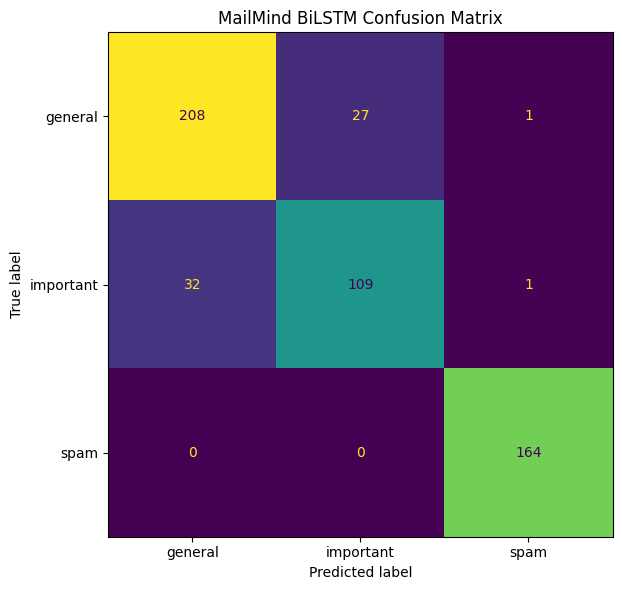

In [69]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(
    ax=ax,
    colorbar=False
)

plt.title(
    "MailMind BiLSTM Confusion Matrix"
)

plt.tight_layout()

plt.show()

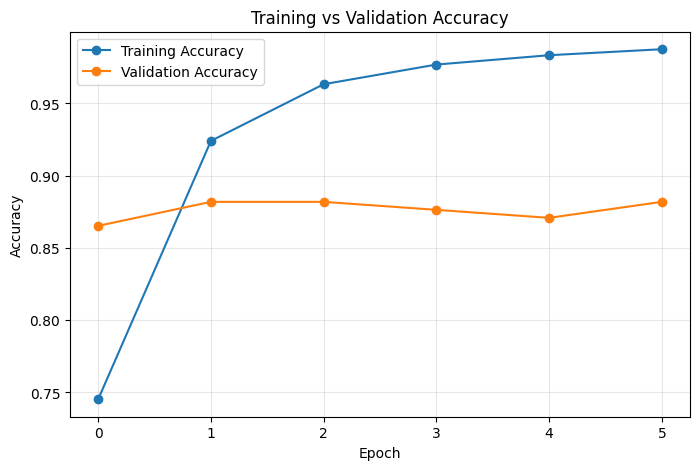

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

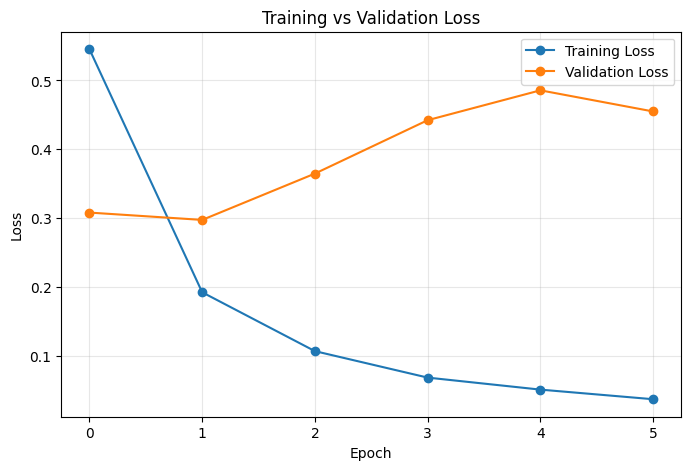

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "Training vs Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

In [46]:
MODEL_DIR = "models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "mailmind_email_bilstm_v1.keras"
)

model.save(
    MODEL_PATH
)

print(
    "Model saved to:",
    MODEL_PATH
)

Model saved to: models\mailmind_email_bilstm_v1.keras


In [47]:
TOKENIZER_DIR = "tokenizers"

os.makedirs(
    TOKENIZER_DIR,
    exist_ok=True
)

with open(
    os.path.join(
        TOKENIZER_DIR,
        "sender_tokenizer.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        sender_tokenizer,
        f
    )


with open(
    os.path.join(
        TOKENIZER_DIR,
        "subject_tokenizer.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        subject_tokenizer,
        f
    )


with open(
    os.path.join(
        TOKENIZER_DIR,
        "body_tokenizer.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        body_tokenizer,
        f
    )

print("All tokenizers saved.")

All tokenizers saved.


In [48]:
with open(
    os.path.join(
        TOKENIZER_DIR,
        "email_label_encoder.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        label_encoder,
        f
    )

print("Label encoder saved.")

Label encoder saved.


In [51]:
def predict_email(
    sender,
    subject,
    body
):

    # sender = clean_text(sender)
    # subject = clean_text(subject)
    # body = clean_text(body)

    # Sender
    sender_seq = sender_tokenizer.texts_to_sequences(
        [sender]
    )

    sender_pad = pad_sequences(
        sender_seq,
        maxlen=SENDER_MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Subject
    subject_seq = subject_tokenizer.texts_to_sequences(
        [subject]
    )

    subject_pad = pad_sequences(
        subject_seq,
        maxlen=SUBJECT_MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Body
    body_seq = body_tokenizer.texts_to_sequences(
        [body]
    )

    body_pad = pad_sequences(
        body_seq,
        maxlen=BODY_MAX_LEN,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(
        [
            sender_pad,
            subject_pad,
            body_pad
        ],
        verbose=0
    )[0]

    predicted_index = np.argmax(
        probabilities
    )

    predicted_label = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    confidence = probabilities[
        predicted_index
    ]

    return {
        "label": predicted_label,
        "confidence": float(confidence),
        "probabilities": {
            label_encoder.classes_[i]:
            float(probabilities[i])
            for i in range(NUM_CLASSES)
        }
    }

In [52]:
result = predict_email(

    sender="cdc@vit.ac.in",

    subject="Microsoft Placement Drive",

    body="""
    Dear Students,

    Microsoft will be visiting the VIT campus
    for the upcoming placement drive.

    Eligible students are requested to register
    before the deadline.

    Regards,
    Career Development Centre
    """
)

print(result)

{'label': 'important', 'confidence': 0.8744857907295227, 'probabilities': {'general': 0.1250806450843811, 'important': 0.8744857907295227, 'spam': 0.0004335719859227538}}


In [54]:
test_1 = predict_email(
    sender="placements@vit.ac.in",
    subject="Accenture Placement Drive – Registration Open",
    body="""
Dear Students,

Accenture will be conducting an on-campus recruitment drive next week.
Eligible students must complete the registration form before Friday, 5:00 PM.

The assessment schedule and eligibility criteria are available in the attached notice.

Regards,
Career Development Centre
"""
)

print(test_1)

{'label': 'important', 'confidence': 0.5410297513008118, 'probabilities': {'general': 0.4569751024246216, 'important': 0.5410297513008118, 'spam': 0.0019951926078647375}}


In [55]:
test_2 = predict_email(
    sender="faculty.cse@vit.ac.in",
    subject="Operating Systems – Internal Assessment Schedule",
    body="""
Dear Students,

The Internal Assessment 2 for Operating Systems will be conducted on
September 5 during the regular class hours.

Please make sure you attend the assessment and bring your university ID card.

Regards,
Department of Computer Science
"""
)

print(test_2)

{'label': 'important', 'confidence': 0.7032778859138489, 'probabilities': {'general': 0.29541853070259094, 'important': 0.7032778859138489, 'spam': 0.0013035617303103209}}


In [57]:
test_3 = predict_email(
    sender="events@vit.ac.in",
    subject="Invitation: AI and Future of Software Development",
    body="""
Dear Students,

The School of Computing is organizing a guest lecture on artificial
intelligence and the future of software development this Friday at 4 PM.

Interested students are welcome to attend.

Regards,
VIT Events Team
"""
)

print(test_3)

{'label': 'important', 'confidence': 0.7959356904029846, 'probabilities': {'general': 0.20297719538211823, 'important': 0.7959356904029846, 'spam': 0.0010871454142034054}}


In [58]:
test_4 = predict_email(
    sender="studentservices@vit.ac.in",
    subject="Action Required: Update Student Information",
    body="""
Dear Student,

All students are required to verify and update their contact information
on the student portal before August 31.

Please complete the process before the deadline to avoid issues with
university communication.

Regards,
Student Services
"""
)

print(test_4)

{'label': 'important', 'confidence': 0.8224945664405823, 'probabilities': {'general': 0.17676018178462982, 'important': 0.8224945664405823, 'spam': 0.0007452351856045425}}


In [61]:
test_5 = predict_email(
    sender="newsletter@techcommunity.org",
    subject="August Technology Newsletter",
    body="""
Hello,

Here is this month's technology newsletter featuring articles on cloud
computing, artificial intelligence, cybersecurity and software engineering.

We hope you enjoy reading it.

Regards,
Tech Community
"""
)

print(test_5)

{'label': 'general', 'confidence': 0.5565621852874756, 'probabilities': {'general': 0.5565621852874756, 'important': 0.12288551032543182, 'spam': 0.32055234909057617}}


In [62]:
test_6 = predict_email(
    sender="innovation@vit.ac.in",
    subject="Student Innovation Challenge 2026",
    body="""
Dear Students,

Applications are now open for the Student Innovation Challenge 2026.

Students interested in developing innovative solutions are encouraged to
participate. Selected teams will receive mentoring and an opportunity to
present their projects.

Regards,
Innovation Cell
"""
)

print(test_6)

{'label': 'general', 'confidence': 0.9127100706100464, 'probabilities': {'general': 0.9127100706100464, 'important': 0.08623428642749786, 'spam': 0.0010555620538070798}}


In [63]:
test_7 = predict_email(
    sender="offers@wealthgrowth-now.com",
    subject="Congratulations! You Have Been Selected",
    body="""
Congratulations!

You have been selected to receive an exclusive cash reward of $25,000.

Click the link below immediately to claim your prize.
This limited offer expires today.

Regards,
Rewards Department
"""
)

print(test_7)

{'label': 'spam', 'confidence': 0.7168893218040466, 'probabilities': {'general': 0.0195196233689785, 'important': 0.26359108090400696, 'spam': 0.7168893218040466}}


In [64]:
test_8 = predict_email(
    sender="loanapproval@quickcash-finance.com",
    subject="Your Loan Has Been Pre-Approved",
    body="""
Dear Customer,

Your personal loan of $50,000 has been pre-approved with no credit check.

To receive your money today, submit your bank account information using
the link below.

Limited-time processing offer available now.

Regards,
QuickCash Finance
"""
)

print(test_8)

{'label': 'spam', 'confidence': 0.9451680183410645, 'probabilities': {'general': 0.00761002954095602, 'important': 0.04722198471426964, 'spam': 0.9451680183410645}}


In [65]:
test_9 = predict_email(
    sender="sales@naturalhealth-solution.com",
    subject="Lose Weight Fast – Special Offer",
    body="""
Discover our revolutionary natural formula for rapid weight loss.

Thousands of customers are already seeing incredible results.
Order today and receive 70% off plus free delivery.

This offer ends tonight.

Click here to place your order.
"""
)

print(test_9)

{'label': 'spam', 'confidence': 0.9997078776359558, 'probabilities': {'general': 0.00019628359586931765, 'important': 9.584060171619058e-05, 'spam': 0.9997078776359558}}


In [67]:
test_10 = predict_email(
    sender="cdc@vit.ac.in",
    subject="Microsoft Placement Drive – Eligible Students",
    body="""
Dear Students,

Microsoft will be visiting the VIT campus for the upcoming placement drive.

Eligible students are requested to register before the deadline.

Please check the placement portal for eligibility requirements and further
instructions.

Regards,
Career Development Centre
"""
)

print(test_10)

{'label': 'important', 'confidence': 0.7323434352874756, 'probabilities': {'general': 0.26716673374176025, 'important': 0.7323434352874756, 'spam': 0.0004898218321613967}}
